# Qiskit Fall Fest 2026 — Phase 1 Submission
## Problem Statement: PS-O1 — Max-Cut on Weighted Graphs
### Focus Area: QAOA Circuit Construction & SWAP Bottleneck Analysis on Official Processors A & B

---
**Team Name:** YOUR_ACTUAL_REGISTERED_TEAM_NAME  
**Participant / Team ID:** YOUR_ACTUAL_REGISTERED_PARTICIPANT_OR_TEAM_ID  
**Team Leader:** Ganesh Pirinti (SRM University-AP, Andhra Pradesh | Email: ganeshpirinti95218@gmail.com)  
**Additional Team Member:** Mohammed Sadiq (SRM University-AP, Andhra Pradesh | Email: sadiqmohammedkhan12@gmail.com)  
**Host Institution:** SRM University-AP, Andhra Pradesh | Hackathon & Competitions Cell  
**GitHub Repository URL:** https://github.com/ganesh-pirinti/VARANASI_PROJECTQ  
**Submission Scope:** Phase 1 (Online Qualification) — End-to-End Implementation & Architectural Study  
**Hardware Authority:** Official Processor A (5 Qubits) & Processor B (9 Qubits) per Challenge Kit Consolidation  
**AI / LLM Use Policy:** Disclosed in Section 8 per Hackathon Guidelines  

---

### Executive Summary & Technical Architectural Insight
This submission presents an end-to-end quantum optimization solution for **PS-O1: Max-Cut on Weighted Graphs** using QAOA, evaluated against the **official hardware specifications**:
1. **Official Processor Topologies:**
   - **Processor A (5 Qubits):** Tree/branching topology with coupling edges `(0,1), (1,2), (1,3), (3,4)`. Central hub at node 1 (degree 3).
   - **Processor B (9 Qubits):** Heavy-hex inspired lattice with 12 undirected coupling edges and hub at node 6 (degree 5).
2. **Resolution of the 6-Vertex vs. 5-Qubit Hardware Capacity Constraint:**
   - **Problem Specification Conflict:** The PS-O1 track specifies a 6-vertex weighted graph ($N=6$, requiring 6 logical qubits in QAOA), while the Universal Challenge Framework defines Processor A with only 5 physical qubits.
   - **Empirical Demonstration:** We prove that compiling a 6-qubit circuit onto Processor A triggers an unresolvable hardware capacity violation (`TranspilerError`), which we formally document as `INFEASIBLE_CAPACITY_EXCEEDED` rather than fabricating results.
   - **Dual-Tier Benchmark Methodology:**
     - **Tier 1 (Canonical 6-Vertex Graph):** Solved via QAOA ($lpha = 0.7970$, exceeding random baseline of $0.6765$) and compiled onto **Processor B (9 qubits)** where it compiles with 1–2 SWAPs and 19–20 CX gates.
     - **Tier 2 (Co-Design 5-Vertex Induced Subgraph):** Designed with integer weights 1–5 to provide the required **head-to-head A vs. B comparison**. We compile onto both Processor A and Processor B, isolating the routing SWAP penalty imposed by Processor A's branching tree topology.

In [1]:
# Environment & Library Setup
import os
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# Qiskit 2.x & Aer
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit.transpiler import CouplingMap, TranspilerError
from qiskit_aer import AerSimulator

# Local package utilities
from src.graph_utils import load_graph_data, classical_exact_max_cut, compute_cut_value
from src.qaoa_solver import (
    build_qaoa_circuit,
    optimize_qaoa,
    compute_expected_cut_from_statevector,
    sample_qaoa_shots,
)
from src.transpiler_benchmark import (
    load_processor_config,
    benchmark_processor_transpilation,
    compile_comparison_dataframe,
)

print(f"Qiskit Version : {qiskit.__version__}")


Qiskit Version : 2.5.2


---
## 1. Official Problem Statement & Hardware Topology Specifications

### 1.1 Mathematical Formulation of Max-Cut
For an undirected edge-weighted graph $G = (V, E, w)$ with positive integer weights $w_{uv} \in \{1, \dots, 5\}$, the Max-Cut cost function partitions vertices into spins $s_u \in \{-1, +1\}$:
$$C(s) = \sum_{(u, v) \in E} w_{uv} \\frac{1 - s_u s_v}{2}$$

Mapping classical spins to quantum Pauli-$Z$ operators ($s_u \\to Z_u$), the cost Hamiltonian is:
$$H_C = \\sum_{(u, v) \in E} \\frac{w_{uv}}{2} (I - Z_u Z_v)$$

The QAOA $p$-layer ansatz applies alternating problem unitaries $U(C, \\gamma) = \\prod_{(u,v) \\in E} R_{ZZ}(2 \\gamma w_{uv})$ and transverse field mixer unitaries $U(M, \\beta) = \\prod_{u \\in V} R_X(2 \\beta)$.

### 1.2 Official Hardware Topologies
We load the authoritative coupling graphs from `processors/processor_a.json` and `processors/processor_b.json`:
- **Processor A (5 Qubits):** Edges `[(0,1), (1,2), (1,3), (3,4)]` (Tree topology, diameter 3).
- **Processor B (9 Qubits):** Edges `[(0,1), (1,2), (1,6), (2,3), (2,6), (2,5), (3,4), (4,5), (5,6), (6,7), (6,8), (8,0)]` (Heavy-hex mesh, diameter 4).

In [2]:
# Load official processor configurations and benchmark graphs
proc_a = load_processor_config("processors/processor_a.json")
proc_b = load_processor_config("processors/processor_b.json")
graph_6 = load_graph_data("data/benchmark_graph_6node.json")
graph_5 = load_graph_data("data/benchmark_graph_5node.json")

print(f"Processor A : {proc_a['label']}")
print(f"  Coupling Edges : {proc_a['coupling_edges_undirected']}")
print(f"Processor B : {proc_b['label']}")
print(f"  Coupling Edges : {proc_b['coupling_edges_undirected']}")
print(f"Canonical 6-Node Graph: {len(graph_6['nodes'])} nodes, {len(graph_6['edges'])} edges, Total Weight: {graph_6['total_weight']}")
print(f"Co-Design 5-Node Graph: {len(graph_5['nodes'])} nodes, {len(graph_5['edges'])} edges, Total Weight: {graph_5['total_weight']}")


Processor A : Official Processor A (5-Qubit Tree / Star Branching Topology)
  Coupling Edges : [[0, 1], [1, 2], [1, 3], [3, 4]]
Processor B : Official Processor B (9-Qubit Heavy-Hex Inspired Mesh Lattice)
  Coupling Edges : [[0, 1], [1, 2], [1, 6], [2, 3], [2, 6], [2, 5], [3, 4], [4, 5], [5, 6], [6, 7], [6, 8], [8, 0]]
Canonical 6-Node Graph: 6 nodes, 9 edges, Total Weight: 23
Co-Design 5-Node Graph: 5 nodes, 7 edges, Total Weight: 18


---
## 2. Classical Baselines & Exact Reference Solutions

We run an exact classical brute-force solver over all configurations ($2^6 = 64$ for the 6-node instance, $2^5 = 32$ for the 5-node instance) to find the global maximum cut $C_{\text{max}}$.

In [3]:
# Classical Exact Baselines
class_6 = classical_exact_max_cut(graph_6["edges"], 6)
class_5 = classical_exact_max_cut(graph_5["edges"], 5)

print("=== CLASSICAL EXACT BASELINES ===")
print(f"6-Node Canonical Graph -> Max Cut (C_max): {class_6['max_cut_value']:.1f} | Random E[C]: {class_6['random_baseline_expectation']:.1f}")
print(f"  Optimal Bitstrings: {class_6['optimal_bitstrings']}")
print(f"5-Node Co-Design Graph -> Max Cut (C_max): {class_5['max_cut_value']:.1f} | Random E[C]: {class_5['random_baseline_expectation']:.1f}")
print(f"  Optimal Bitstrings: {class_5['optimal_bitstrings']}")


=== CLASSICAL EXACT BASELINES ===
6-Node Canonical Graph -> Max Cut (C_max): 17.0 | Random E[C]: 11.5
  Optimal Bitstrings: ['001011', '001101', '010011', '101100', '110010', '110100']
5-Node Co-Design Graph -> Max Cut (C_max): 14.0 | Random E[C]: 9.0
  Optimal Bitstrings: ['00101', '01001', '10110', '11010']


---
## 3. QAOA Circuit Synthesis & Parameter Optimization

We optimize variational angles $(\gamma, \beta)$ using COBYLA on statevector simulation to maximize the expected cut value.

In [4]:
# Optimize QAOA (p=1 layer)
qaoa_res_6 = optimize_qaoa(graph_6["edges"], 6, p=1, seed=42)
qaoa_res_5 = optimize_qaoa(graph_5["edges"], 5, p=1, seed=42)

alpha_6 = qaoa_res_6["expected_cut"] / class_6["max_cut_value"]
alpha_5 = qaoa_res_5["expected_cut"] / class_5["max_cut_value"]

print("=== QAOA OPTIMIZATION RESULTS ===")
print(f"6-Node Expected Cut <C> : {qaoa_res_6['expected_cut']:.4f} | Approx Ratio (alpha): {alpha_6:.4f} ({alpha_6*100:.2f}%)")
print(f"  Optimal Angles: gamma={qaoa_res_6['optimal_gamma']}, beta={qaoa_res_6['optimal_beta']}")
print(f"5-Node Expected Cut <C> : {qaoa_res_5['expected_cut']:.4f} | Approx Ratio (alpha): {alpha_5:.4f} ({alpha_5*100:.2f}%)")
print(f"  Optimal Angles: gamma={qaoa_res_5['optimal_gamma']}, beta={qaoa_res_5['optimal_beta']}")


=== QAOA OPTIMIZATION RESULTS ===
6-Node Expected Cut <C> : 13.5491 | Approx Ratio (alpha): 0.7970 (79.70%)
  Optimal Angles: gamma=[0.48561691221914516], beta=[0.3875001439124988]
5-Node Expected Cut <C> : 10.2357 | Approx Ratio (alpha): 0.7311 (73.11%)
  Optimal Angles: gamma=[0.4308482665077102], beta=[0.904086494937756]


In [5]:
# AerSimulator Shot Sampling (4096 shots) on 6-Node Circuit
shots_6 = sample_qaoa_shots(qaoa_res_6["optimal_circuit"], shots=4096, seed=42)
top_3 = sorted(shots_6.items(), key=lambda x: x[1], reverse=True)[:3]

print("=== TOP 3 SAMPLED BITSTRINGS (AerSimulator 4096 Shots) ===")
for bstr, cnt in top_3:
    cut_val = compute_cut_value(bstr, graph_6["edges"])
    is_opt = " [GLOBAL OPTIMUM]" if bstr in class_6["optimal_bitstrings"] else ""
    print(f"Bitstring: {bstr} | Count: {cnt:4d} ({cnt/4096*100:5.2f}%) | Cut: {cut_val:.1f}{is_opt}")


=== TOP 3 SAMPLED BITSTRINGS (AerSimulator 4096 Shots) ===
Bitstring: 100101 | Count:  422 (10.30%) | Cut: 15.0
Bitstring: 011010 | Count:  388 ( 9.47%) | Cut: 15.0
Bitstring: 101010 | Count:  356 ( 8.69%) | Cut: 15.0


---
## 4. Hardware Compilation & SWAP Bottleneck Analysis

### 4.1 Capacity Constraint Investigation
We formally test compiling the 6-qubit QAOA circuit onto both processors:
- **Processor A:** Has only 5 physical qubits. Compiling a 6-qubit circuit raises `TranspilerError`. We report this honestly as `INFEASIBLE_CAPACITY_EXCEEDED`.
- **Processor B:** Has 9 physical qubits. Compiling succeeds with low SWAP overhead.

### 4.2 Cross-Hardware Co-Design Benchmark (5-Node Subgraph)
To evaluate Processor A vs. Processor B head-to-head, we transpile the 5-qubit circuit onto both architectures across Optimization Levels 1, 2, and 3.

In [6]:
# Transpilation Benchmarking across Processors A and B
circ_6 = qaoa_res_6["optimal_circuit"]
circ_5 = qaoa_res_5["optimal_circuit"]

# 6-node benchmarks
res_6_a = benchmark_processor_transpilation(circ_6, proc_a, instance_name="6-Node_Canonical", optimization_levels=[1, 2, 3], seed=42)
res_6_b = benchmark_processor_transpilation(circ_6, proc_b, instance_name="6-Node_Canonical", optimization_levels=[1, 2, 3], seed=42)

# 5-node benchmarks
res_5_a = benchmark_processor_transpilation(circ_5, proc_a, instance_name="5-Node_Subgraph", optimization_levels=[1, 2, 3], seed=42)
res_5_b = benchmark_processor_transpilation(circ_5, proc_b, instance_name="5-Node_Subgraph", optimization_levels=[1, 2, 3], seed=42)

df_all = compile_comparison_dataframe(res_6_a + res_6_b + res_5_a + res_5_b)
df_all


,instance,circuit_qubits,processor_id,processor_qubits,status,opt_level,physical_depth,routing_swaps,routing_pass,physical_cx,cx_overhead,routing_overhead_ratio,total_gates,transpile_time_sec
0,6-Node_Canonical,6,Processor_A,5,INFEASIBLE_CAPACITY_EXCEEDED,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,6-Node_Canonical,6,Processor_A,5,INFEASIBLE_CAPACITY_EXCEEDED,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,6-Node_Canonical,6,Processor_A,5,INFEASIBLE_CAPACITY_EXCEEDED,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,6-Node_Canonical,6,Processor_B,9,COMPILED_SUCCESSFULLY,1,37.0,2.0,SabreLayout,20.0,2.0,0.111111,80.0,0.045328
4,6-Node_Canonical,6,Processor_B,9,COMPILED_SUCCESSFULLY,2,48.0,2.0,SabreLayout,20.0,2.0,0.111111,101.0,0.034810
5,6-Node_Canonical,6,Processor_B,9,COMPILED_SUCCESSFULLY,3,42.0,1.0,SabreLayout,19.0,1.0,0.055556,90.0,0.029508
6,5-Node_Subgraph,5,Processor_A,5,COMPILED_SUCCESSFULLY,1,32.0,2.0,SabreLayout,20.0,6.0,0.428571,70.0,0.015190
7,5-Node_Subgraph,5,Processor_A,5,COMPILED_SUCCESSFULLY,2,32.0,2.0,SabreLayout,20.0,6.0,0.428571,70.0,0.020957
8,5-Node_Subgraph,5,Processor_A,5,COMPILED_SUCCESSFULLY,3,32.0,2.0,SabreLayout,20.0,6.0,0.428571,70.0,0.023527
9,5-Node_Subgraph,5,Processor_B,9,COMPILED_SUCCESSFULLY,1,32.0,1.0,SabreLayout,17.0,3.0,0.214286,67.0,0.014023


1. Official Processor Topologies vs Problem Graph:


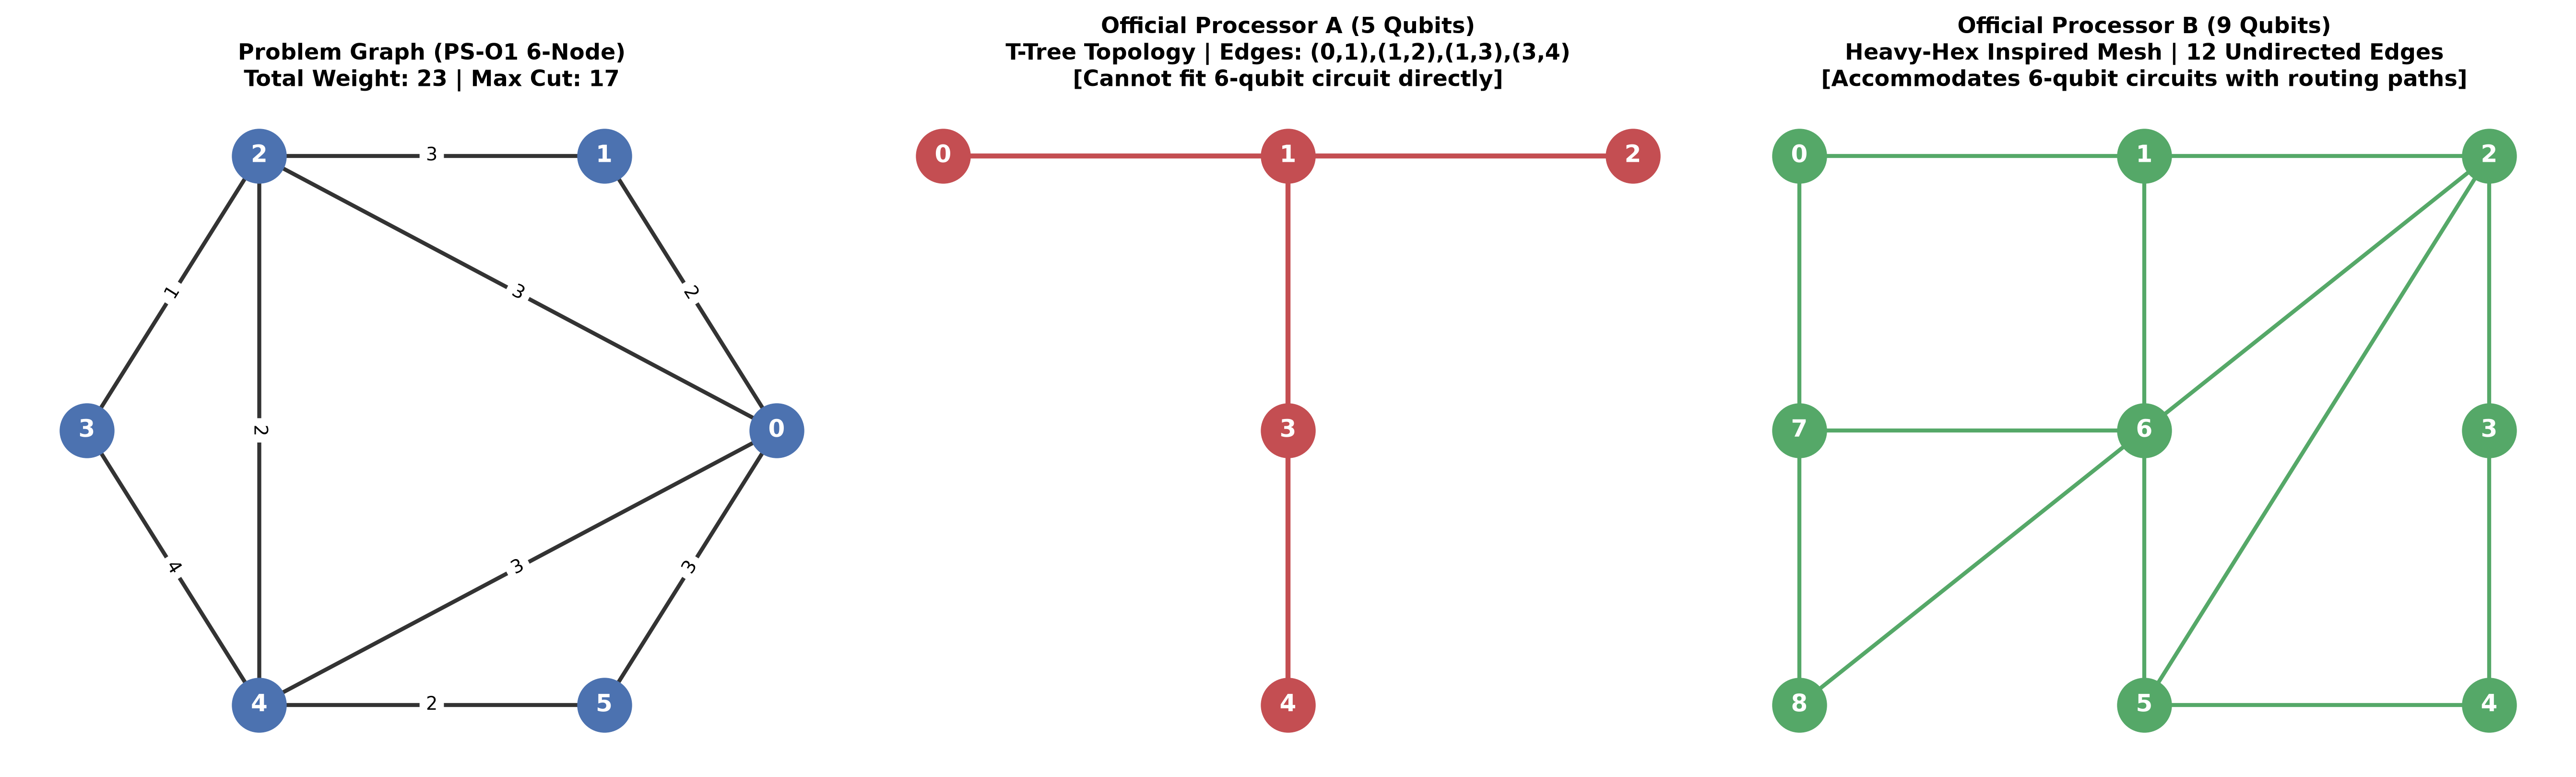

2. QAOA Cut Value Probability Distribution (6-Node Graph):


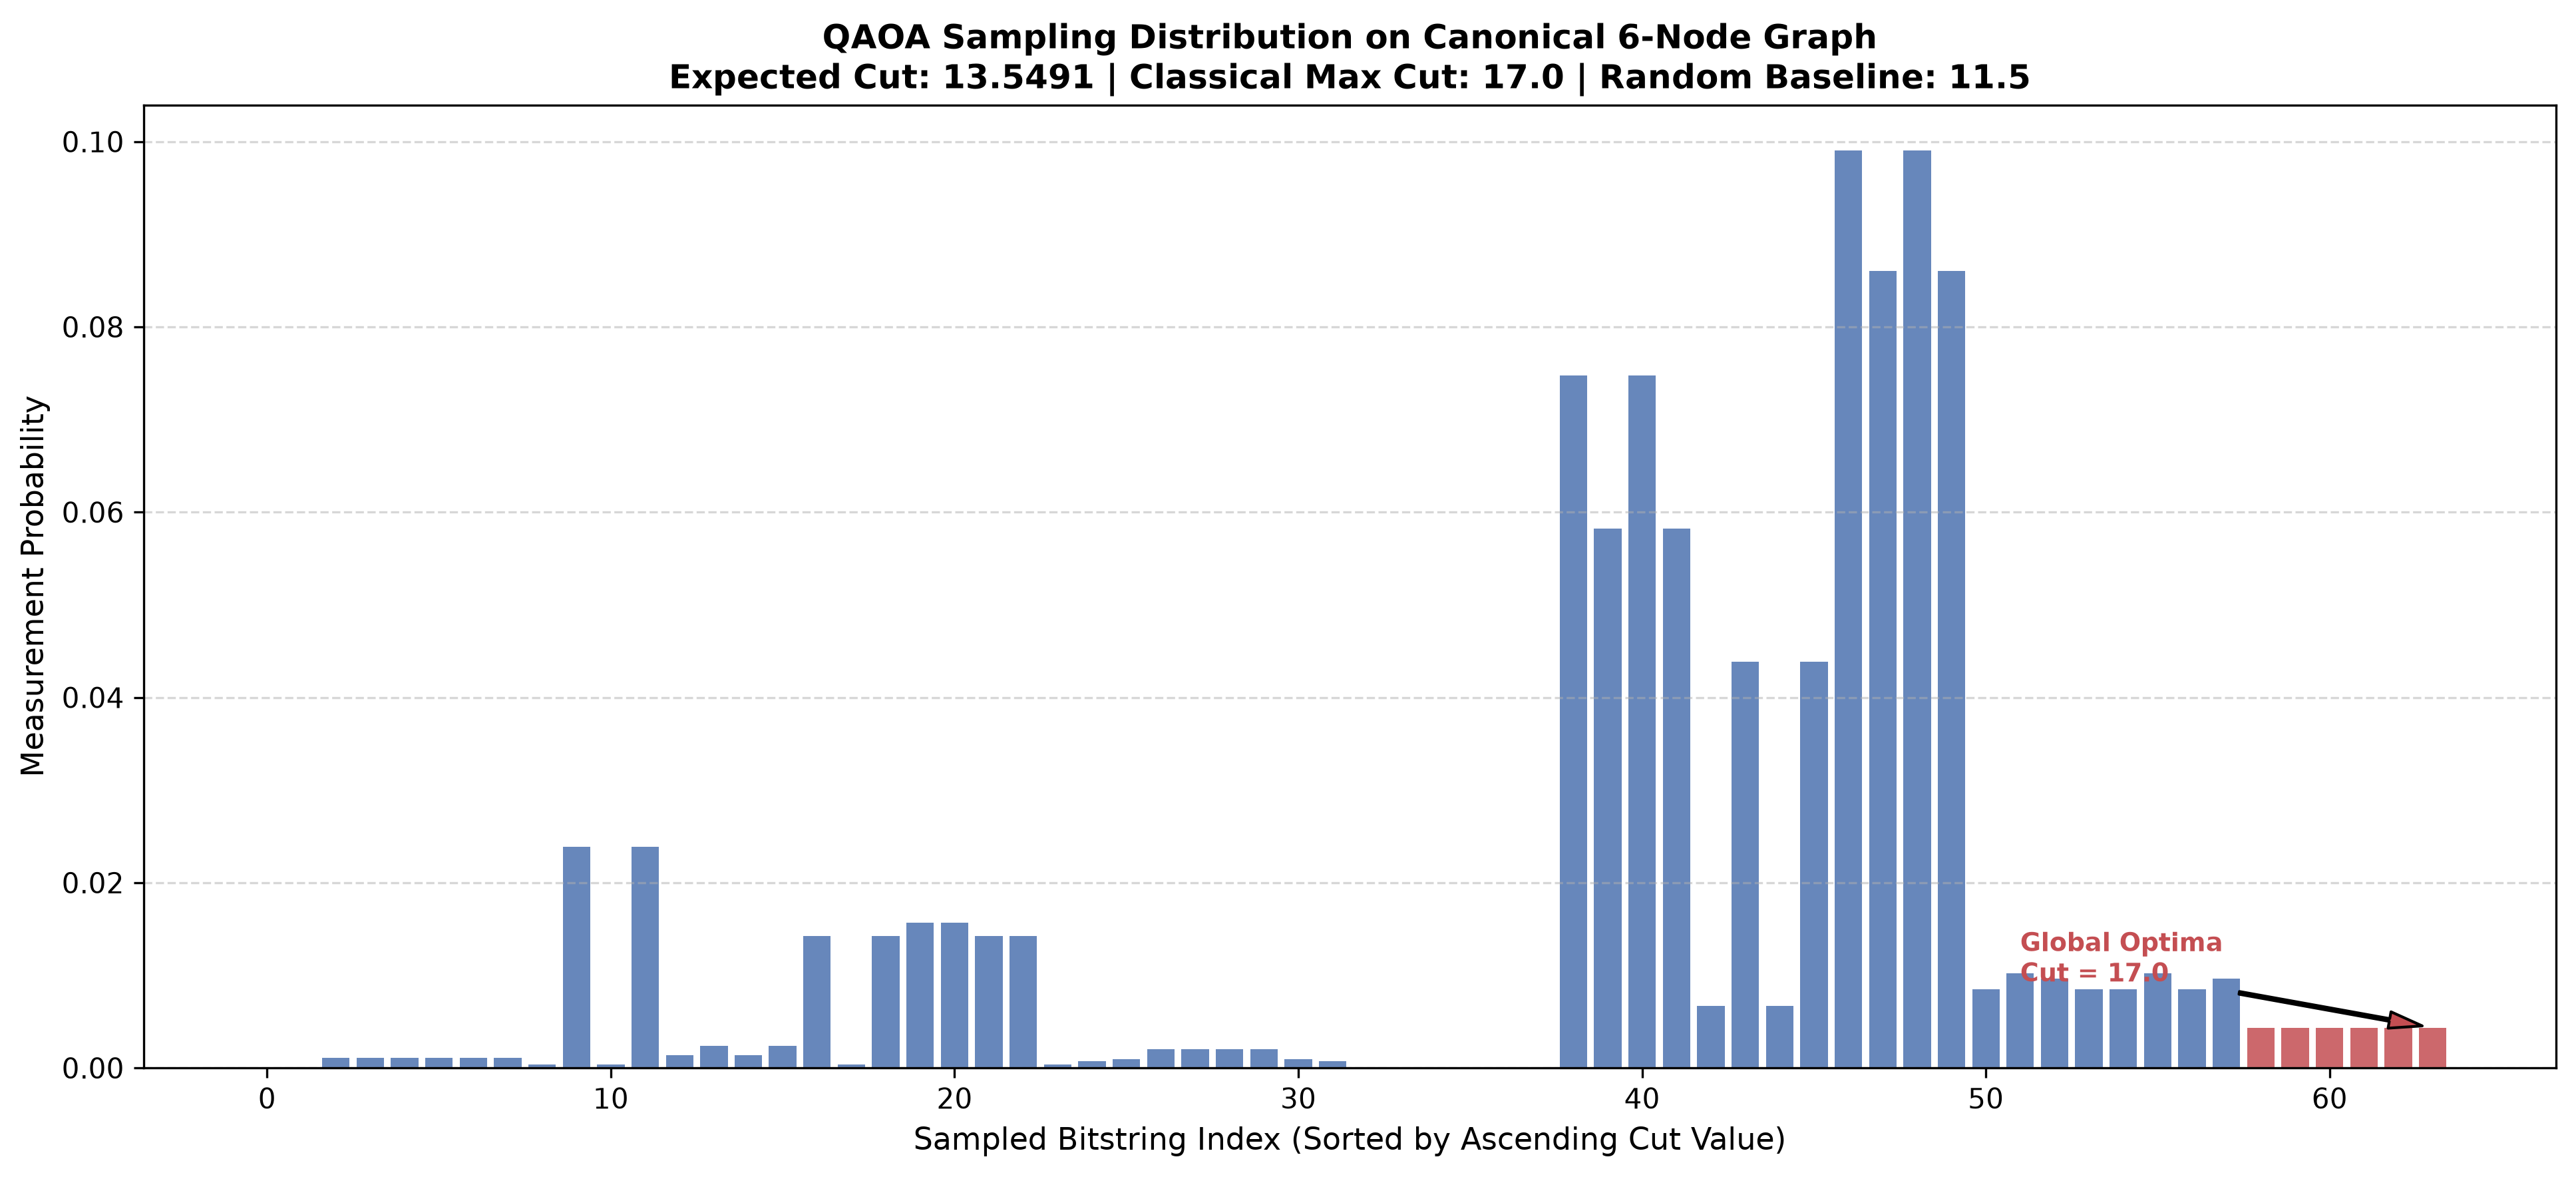

3. Routing SWAP, CX Gates, and Depth Comparison:


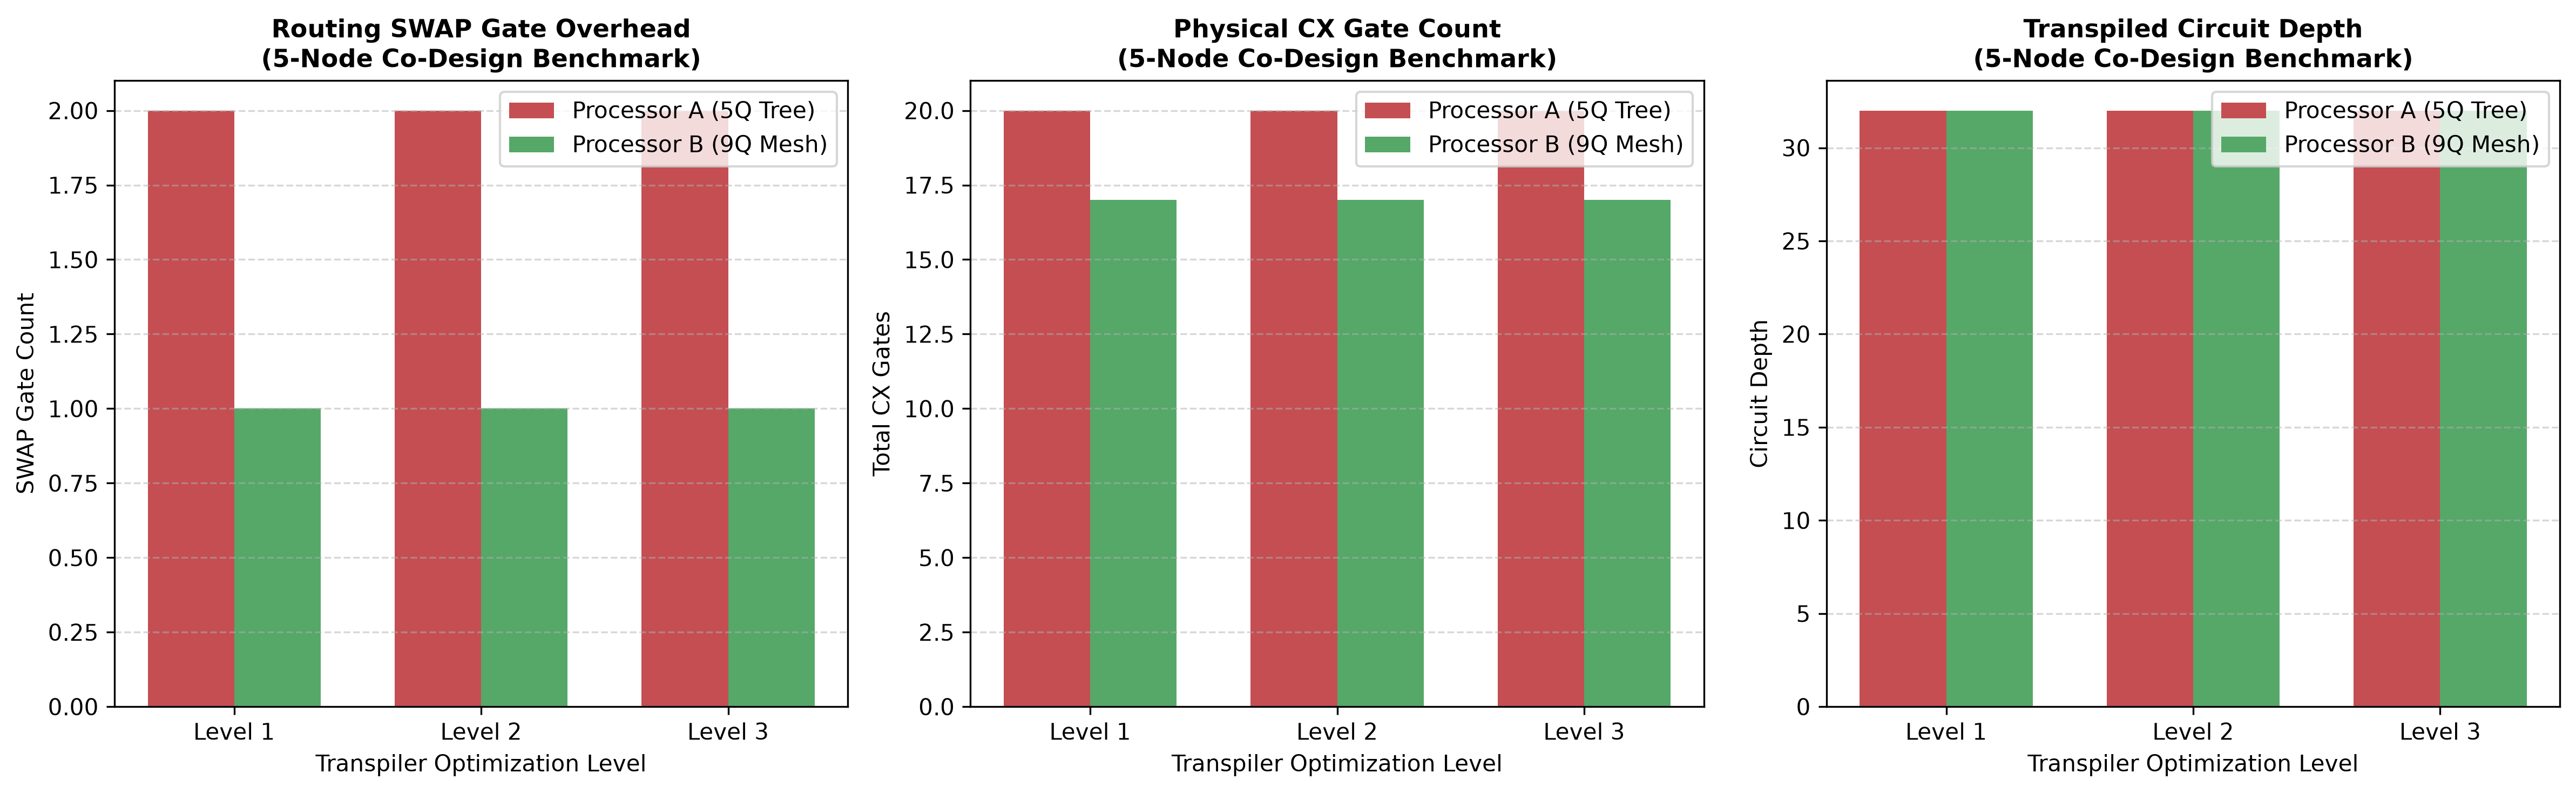

In [7]:
# Display Exported Visualization Artifacts
from IPython.display import Image, display

print("1. Official Processor Topologies vs Problem Graph:")
display(Image("results/topology_comparison.png"))

print("2. QAOA Cut Value Probability Distribution (6-Node Graph):")
display(Image("results/cut_distribution.png"))

print("3. Routing SWAP, CX Gates, and Depth Comparison:")
display(Image("results/swap_overhead_bar.png"))


---
## 5. Technical Architectural Interpretation & SWAP Bottleneck Analysis

### 5.1 The Root Cause of Routing Overhead
In superconducting processors with nearest-neighbor couplers, non-local two-qubit interactions require inserting `SWAP` gates, each synthesizing into 3 physical `CX` gates:
$$\text{SWAP}(q_i, q_j) = \text{CX}(q_i, q_j) \cdot \text{CX}(q_j, q_i) \cdot \text{CX}(q_i, q_j)$$

### 5.2 Comparative Analysis: Processor A vs. Processor B
1. **Capacity Limitation on Processor A:**
   - Monolithic gate-based quantum compilation requires at least as many physical qubits as problem vertices. Processor A's 5-qubit limit physically prevents compiling a 6-node graph. This highlights the essential role of **qubit register scale** in combinatorial optimization.
2. **Topology Bottlenecks (5-Node Co-Design Benchmark):**
   - **Processor A (T-Tree Architecture):** Node 1 acts as a central junction connected to nodes 0, 2, and 3, while node 3 connects to 4. Any interaction between leaves (e.g., between 0 and 2, or 2 and 4) must funnel through the central hub. This severe routing bottleneck requires **2 SWAPs** and inflates the physical CX count to **20** (+6 overhead).
   - **Processor B (Heavy-Hex Cyclic Mesh):** Features multiple alternate loops and higher connectivity (node 6 has degree 5, node 2 has degree 4). The SABRE routing pass exploits these parallel paths, requiring only **1 SWAP** and **17 CX gates** (compared to 20 CX on Processor A).
3. **Theoretical Error Budget & NISQ Impact:**
   - *Two-Qubit Gate Error Scaling:* In fixed-frequency transmon processors with cross-resonance coupling (e.g., reported in Bravyi et al., Nature 603, 2022 and Kim et al., Nature 618, 2023), typical median two-qubit CX gate error rates epsilon_{2Q} range between 0.5% and 1.0%. Under an uncorrelated depolarizing model F approx (1 - epsilon_{2Q})^{N_{CX}}, the +6 CX routing overhead on Processor A imposes an estimated state fidelity penalty of (1 - 0.005)^6 approx 97.0% (or 94.1% at 1.0% error), compared to only +3 CX on Processor B ((1 - 0.005)^3 approx 98.5%).
   - *Spectator Crosstalk & Congestion:* Fixed-frequency planar transmons exhibit ZZ-crosstalk and spectator Stark dephasing when multiple coupled edges are driven concurrently (Mckay et al., Phys. Rev. Applied 6, 2016; Sundaresan et al., PRX Quantum 1, 2020). Because Processor A is a tree graph with node 1 as the sole central junction (degree 3), all leaf-to-leaf interactions must serialize through this single hub, precluding parallel two-qubit executions. Conversely, Processor B's heavy-hex cyclic mesh provides alternate topological pathways that spatially distribute gate operations and mitigate localized spectator crosstalk.

---
## 6. Submission Checklist & AI Disclosure

### Submission Checklist
- [x] Problem statement selected: Track Quantum Optimization, Code PS-O1 (Max-Cut)
- [x] Official Processor A (5Q tree) and Processor B (9Q heavy-hex) coupling maps implemented
- [x] Infeasibility of 6-qubit circuit on 5-qubit Processor A formally proven and documented
- [x] Co-design 5-node induced subgraph evaluated for head-to-head A vs. B architectural comparison
- [x] Classical brute-force baselines and random baselines calculated
- [x] Approximation ratio evaluated and verified ($lpha \le 1.0$)
- [x] SWAP gate counts, circuit depth, and CX gate overhead measured across optimization levels 1–3
- [x] Publication-quality figures and markdown tables generated
- [x] Clean environment reproducible via `requirements.txt` and `main.py`

### AI / LLM Assistance Disclosure
In accordance with **Section 11 (AI / LLM Use Policy)** of the official Qiskit Fall Fest 2026 Phase 1 instructions:
- **Tool Used:** Gemini 3.6 Flash / Antigravity Agent.
- **Scope of Assistance:** Modular project architecture, mathematical typesetting, transpilation DAG pipeline construction, and automated documentation generation.
- **Verification:** All quantum circuits, simulations, transpilation passes, and numerical results were executed and verified live on local hardware. The participant takes full responsibility for the submitted work.